# 02 · Aspect satisfaction — warranty / guarantee

**Project 2 · Problem 2 · Part 2.** For every product we want the average `overall` rating of the reviews that talk about the **warranty / guarantee**, as a rough measure of how satisfied buyers are with that aspect.

A plain search for the two words misses misspellings (`warrenty`, `gaurantee`) and related wording. The pipeline therefore has three steps:

1. **Spelling variants** found in the real vocabulary by edit distance, then **reviewed by hand** (edit distance also returns false friends such as `warcraft`).
2. **Semantic neighbours** from word embeddings trained on the reviews themselves.
3. **Whole-word matching** on the review text, then a per-product average with a minimum number of reviews.

**Embeddings.** We use *PPMI + truncated SVD* word vectors (co-occurrence window of 5 words, 150 dimensions). This is the count-based counterpart of word2vec (Levy & Goldberg, 2015), needs no extra package, and is trained on in-domain text, so it also contains the typos and jargon of these reviews. `gensim.Word2Vec` could be swapped in with the same interface.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make `src` importable when running from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src import config, data, aspect

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 160)

In [2]:
train = data.load_train(columns=["overall", "asin", "reviewText"])
products = data.load_products()
print(f"train: {len(train):,} reviews | products table: {len(products):,} ASINs")

train: 838,944 reviews | products table: 756,077 ASINs


## 1 · Spelling variants (edit distance)
We count the vocabulary on a **random** sample of 400,000 reviews (the file is sorted by ASIN, so `head()` would be biased) and list words within edit distance 3 of each target.

In [3]:
# Random sample (the file is sorted by ASIN, so head() would be biased towards a few product families).
sample_vocab = train["reviewText"].sample(400_000, random_state=config.SEED)
vocab = aspect.count_vocabulary(sample_vocab)
print(f"vocabulary of the sample: {len(vocab):,} distinct words")

TARGETS = ["warranty", "guarantee"]
for target in TARGETS:
    print(f"\nWords within edit distance 3 of '{target}' (seen at least 3 times):")
    display(aspect.spelling_candidates(target, vocab).head(20))

vocabulary of the sample: 124,416 distinct words

Words within edit distance 3 of 'warranty' (seen at least 3 times):


,word,count,edit_distance
0,warranty,10273,0
1,warrant,230,1
2,warrants,72,1
3,warrenty,62,1
4,waranty,11,1
5,warrany,4,1
6,watranty,3,1
7,warrantly,3,1
8,warranted,126,2
9,warrantee,111,2



Words within edit distance 3 of 'guarantee' (seen at least 3 times):


,word,count,edit_distance
0,guarantee,854,0
1,guaranteed,312,1
2,guarantees,70,1
3,guarentee,7,1
4,guarrantee,3,1
5,guaranty,13,2
6,warantee,5,2
7,gaurantee,3,2
8,granted,927,3
9,warrantee,111,3


**What we keep.** Real variants: `warrenty`, `waranty`, `warrany`, `watranty`, `warrantly`, `warrantee(s)`, `warrantied`, `warantee`, `warrentee`, `warenty`, `warranties`, `guarantees`, `guaranty`, `guarentee`, `guarrantee`, `gaurantee(s)`.

**What we reject** (edit distance is only a candidate generator): `warrant`, `warrants`, `warranted` (the verb "to deserve"), `warcraft`, `marantz`, `variant(s)`, `arrange`, `errant`, `granted`, `quarantine`.

## 2 · Semantic neighbours (embeddings)

In [4]:
# Decisions after reading the candidates above (and the neighbours of the next section).
# A: spellings / inflections of the two target words. Edit distance also returned false friends
#    that are deliberately NOT used: warcraft, granted, warrant(s)/warranted/warranting (verb "to deserve").
SPELLING = [
    "warranty", "warranties", "warrenty", "waranty", "warrantee", "warrantees", "warrantied",
    "warantee", "warrentee", "warenty", "warrantly", "warrany", "watranty",
    "guarantee", "guarantees", "guaranty", "guarentee", "guarrantee", "gaurantee", "gaurantees",
]
# B: warranty-process words that the embedding neighbours surfaced and that we checked in context.
PROCESS = ["rma", "squaretrade", "warrantech"]    # squaretrade and warrantech are third-party warranty providers
# Considered but rejected (reported in the table below for transparency):
BROAD = ["policy", "replacement", "refund", "return", "repair", "claim", "lifetime", "expired", "expires", "manufacturer"]
AMBIGUOUS = ["guaranteed", "honor", "honored", "honoring"]   # "guaranteed to have dying batteries"; "honor" = rebates, returns, the game For Honor, Huawei Honor phones, ...

WORD_LIST = SPELLING + PROCESS
print(f"{len(WORD_LIST)} words used:", WORD_LIST)

23 words used: ['warranty', 'warranties', 'warrenty', 'waranty', 'warrantee', 'warrantees', 'warrantied', 'warantee', 'warrentee', 'warenty', 'warrantly', 'warrany', 'watranty', 'guarantee', 'guarantees', 'guaranty', 'guarentee', 'guarrantee', 'gaurantee', 'gaurantees', 'rma', 'squaretrade', 'warrantech']


In [5]:
sample_emb = train["reviewText"].sample(120_000, random_state=config.SEED + 1)
top_words = [w for w, _ in vocab.most_common(15_000)]
extra = [w for w in SPELLING + PROCESS + BROAD + AMBIGUOUS if w in vocab and w not in top_words]
vocab_words = top_words + extra

embeddings, w2i = aspect.build_embeddings(sample_emb, vocab_words)
print("embedding matrix:", embeddings.shape)

neighbours = pd.concat(
    {t: aspect.nearest(embeddings, vocab_words, w2i, t, k=15).set_index("word")["cosine"] for t in TARGETS}, axis=1)
neighbours

embedding matrix: (15016, 150)


,warranty,guarantee
word,,
honor,0.84,0.76
policy,0.82,NaN
manufacturer,0.82,NaN
rma,0.82,NaN
sent,0.79,NaN
replacement,0.79,NaN
return,0.78,NaN
expired,0.78,NaN
company,0.78,NaN


**Reading the neighbours.** Embedding neighbours are *topical*, not synonyms: they are words that appear in the same kind of sentence (`policy`, `manufacturer`, `refund`, `repair`, `expired`, `lifetime`, ...). Using them blindly would flood the data with reviews about Amazon's return policy. For `guarantee` the neighbours are even less specific (`promise`, `assured`, `evaluate`, `financial`).
Three words are warranty-specific and were checked in context below: **`rma`** (return-authorisation step of a manufacturer repair/replacement), **`squaretrade`** and **`warrantech`** (third-party warranty providers; `warrantech` came from the edit-distance list and is rare).

## 3 · Choosing the final word list
For every group we measure how many reviews it matches and their mean rating, and read random hits in context.

In [6]:
reviews = train["reviewText"]
overall_mean = train["overall"].mean()

def tier_row(name, words):
    hit = aspect.contains_any(reviews, words)
    return {"group": name, "n_reviews": int(hit.sum()), "mean_overall": round(train.loc[hit, "overall"].mean(), 3)}

tier_table = pd.DataFrame([
    tier_row("A spellings (used)", SPELLING),
    tier_row("B process words (used)", PROCESS),
    tier_row("A + B (final list)", WORD_LIST),
    tier_row("broad words (rejected)", BROAD),
    tier_row("ambiguous words (rejected)", AMBIGUOUS),
])
print(f"mean rating of ALL reviews: {overall_mean:.3f}")
tier_table

mean rating of ALL reviews: 4.021


,group,n_reviews,mean_overall
0,A spellings (used),17785,3.189
1,B process words (used),2053,2.478
2,A + B (final list),19242,3.133
3,broad words (rejected),77012,3.204
4,ambiguous words (rejected),1606,3.088


In [7]:
# Precision check in context: random hits for every word that is NOT a plain spelling of the targets.
rng = np.random.default_rng(config.SEED)
lowered = reviews.fillna("").str.lower()
no_spelling = ~aspect.contains_any(reviews, SPELLING)      # for "honor": only reviews the spellings would NOT already catch
for word in ["rma", "squaretrade", "warrantech", "guaranteed", "policy", "honor"]:
    hit = aspect.contains_any(reviews, [word])
    if word == "honor":
        hit = aspect.contains_any(reviews, ["honor", "honored", "honoring"]) & no_spelling
    idx = np.flatnonzero(hit.to_numpy())
    print(f"--- {word}: {len(idx):,} reviews" + (" without any warranty/guarantee spelling" if word == "honor" else ""))
    for i in rng.choice(idx, min(4, len(idx)), replace=False):
        s = lowered.iat[i]; pos = s.find("honor" if word == "honor" else word)
        print(f"  ...{s[max(0, pos - 70): pos + len(word) + 70]}...".replace("\n", " "))

--- rma: 1,858 reviews
  ... get someone to talk to me on the phone fairly quickly who created an rma for repair. the hassle is i had to run to bestbuy to buy a replacemen...
  ...i just sent in the rma after 6mo of buying the first. rma process was easy they sent me a ne...
  ...for it to work. i would usually consider that enough reason to return/rma because i'm not getting what i payed for, but for the great price, i ...
  ...elf works great, no fault on it for the low score, just beware of the rma service.  the product alone does the job at usual speeds you would se...
--- squaretrade: 193 reviews
  ...orth it and in a few years i'll have to buy them again.  i bought the squaretrade warranty to help extend the battery life and protect my investment. i...
  ...laptop that broke after only four months of light usage. i sent it to squaretrade for repair, with the accident protection plan that i purchased.  the ...
  ...nd fast the entire claim process was. i will definitely be adding 

**Decisions.**

| Group | Decision | Reason |
|---|---|---|
| A: spellings and inflections of *warranty* / *guarantee* | **use** | unambiguous |
| B: `rma`, `squaretrade`, `warrantech` | **use** | checked in context, they describe the warranty-claim process or a warranty provider |
| broad words (`policy`, `refund`, `return`, `repair`, ...) | **reject** | ~77k reviews, mostly about Amazon's return policy or ordinary returns, not the product warranty |
| `guaranteed` | **reject** | "guaranteed to have dying batteries", "alignment is guaranteed": not a warranty |
| `honor`, `honored`, `honoring` | **reject** | Beyond the reviews that already contain a warranty spelling they add only ≈ 250 reviews, and those are mostly **not** about warranties: rebates and return promises ("refuse to honor rebates"), the game *For Honor*, Huawei Honor phones (≈ 15 % of them), "your honor", "the honor of receiving" |

The embedding step suggested `honor` as the nearest neighbour of *warranty* (cosine 0.84). Reading the hits showed that it is a topical neighbour, not a synonym. Real "honor the warranty" sentences already contain the word *warranty* (group A), so dropping `honor` costs almost nothing. Some of the dropped customer-service hits ("honored my claim") are genuinely related, so this is a precision-over-recall choice.

## 4 · Matching reviews and per-product satisfaction

In [8]:
train["mentions_warranty"] = aspect.contains_any(train["reviewText"], WORD_LIST)
mentions = train[train["mentions_warranty"]]
print(f"reviews that discuss the warranty: {len(mentions):,} ({len(mentions) / len(train):.2%} of all reviews)")
print(f"their mean rating: {mentions['overall'].mean():.3f}  vs  all reviews: {overall_mean:.3f}")

reviews that discuss the warranty: 19,242 (2.29% of all reviews)
their mean rating: 3.133  vs  all reviews: 4.021


**Interpretation warning.** Reviews that mention the warranty average **≈ 3.13 stars versus 4.02 for all reviews**. People write about a warranty mostly when something broke, so this rating measures *satisfaction in the moment of a problem*, not satisfaction with the warranty alone. This is why the table also reports the **difference to the product's own overall average**.

In [9]:
MIN_REVIEWS = 5

per_product = (mentions.groupby("asin")["overall"]
               .agg(n_warranty_reviews="size", warranty_mean_overall="mean").round(3))
product_mean = train.groupby("asin")["overall"].mean().rename("product_mean_overall").round(3)
per_product = (per_product.join(product_mean)
               .assign(difference=lambda d: (d["warranty_mean_overall"] - d["product_mean_overall"]).round(3))
               .reset_index()
               .merge(products[["asin", "brand", "title"]], on="asin", how="left"))
per_product["title"] = per_product["title"].str.slice(0, 70)
per_product["reliable"] = per_product["n_warranty_reviews"] >= MIN_REVIEWS

print(f"products with at least one warranty review: {len(per_product):,}")
print(f"products with at least {MIN_REVIEWS}: {int(per_product['reliable'].sum()):,}  of {train['asin'].nunique():,} products")

cols = ["brand", "title", "n_warranty_reviews", "warranty_mean_overall", "product_mean_overall", "difference"]
reliable = per_product[per_product["reliable"]]
print("\nMost satisfied with the warranty:")
display(reliable.nlargest(10, ["warranty_mean_overall", "n_warranty_reviews"])[cols])
print("Least satisfied with the warranty:")
display(reliable.nsmallest(10, ["warranty_mean_overall", "n_warranty_reviews"])[cols])

products with at least one warranty review: 10,158
products with at least 5: 638  of 90,715 products

Most satisfied with the warranty:


,brand,title,n_warranty_reviews,warranty_mean_overall,product_mean_overall,difference
4493,Syncwire,iPhone Charger Syncwire Lightning Cable - [Apple MFi Certified] - 3.3f,29,5.0,4.470,0.530
1435,Noctua,"Noctua NF-F12 PWM, 4-Pin Premium Quiet Fan (120mm, Brown)",7,5.0,4.703,0.297
7583,Syncwire,Syncwire Lightning to USB A Cable - Nylon Braided [Apple Mfi Certified,7,5.0,4.600,0.400
1325,BlueRigger,BlueRigger Digital Optical Audio Toslink Cable (3 feet),6,5.0,4.607,0.393
4965,Breakthrough Photography,82mm X2 UV Filter For Camera Lenses - UV Protection Photography Filter,6,5.0,4.718,0.282
6890,PNY,PNY Anarchy 8GB Kit (2x4GB) DDR4 2400MHz (PC4-19200) CL15 Desktop Memo,6,5.0,4.762,0.238
10003,KDLINKS,KDLINKS DX2 Full-HD 1080P Front + 720P Rear 290° Super Wide Angle Car,6,5.0,4.066,0.934
141,Pelican,Pelican 1510 Case With Foam (Black),5,5.0,4.711,0.289
2885,Snugg,"Macbook Pro 15 Sleeve, Snugg - Brown Leather Sleeve Case Protective Co",5,5.0,4.588,0.412
4711,Anker,Anker USB 3.0 4-Port Portable Aluminum Hub with 2-Foot USB 3.0 Cable (,5,5.0,4.314,0.686


Least satisfied with the warranty:


,brand,title,n_warranty_reviews,warranty_mean_overall,product_mean_overall,difference
413,Thermaltake,Thermaltake BlacX 2.5”/3.5” Sata I/II/III USB 2.0 External Hard Drive,5,1.000,3.561,-2.561
4666,Parrot,Parrot Zik 2.0 Wireless Noise Cancelling Headphones (Black),5,1.000,3.333,-2.333
4748,Pioneer,"Pioneer AVH-X3700BHS DVD Receiver with 6.2-Inch Display, Bluetooth, Si",5,1.000,1.909,-0.909
5891,PNY,PNY 240GB CL4111 Client SSD Internal Memory 2.5-Inch SATA III 6Gbps SS,5,1.000,1.222,-0.222
6138,ViewSonic,ViewSonic VFD820-70 8-Inch Digital Photo Frame (White),5,1.000,2.588,-1.588
7662,Microsoft,"Microsoft Surface Pro 4 (128 GB, 4 GB RAM, Intel Core i5)",5,1.000,3.339,-2.339
10008,NETGEAR,Netgear R7500-200NAS Nighthawk X4 Ultimate Gaming Router - AC2350 4X4,5,1.000,3.472,-2.472
1762,ViewSonic,ViewSonic VFD820-50 8-Inch Digital Photo Frame (Black),6,1.000,2.529,-1.529
8434,VIZIO,VIZIO 32 inches 720 p LED TV D32HN-E0 (2016),6,1.000,3.656,-2.656
6957,Lexar,Lexar JumpDrive S45 128GB USB 3.0 Flash Drive - LJDS45-128ABNL (Black),12,1.083,3.124,-2.041


**Minimum number of reviews.** Only a small fraction of products have enough warranty reviews: of 90,715 products, about 10k have at least one and only **≈ 640 have at least 5**. A mean built from one or two reviews is mostly noise, so the ranking tables use products with **≥ 5 matching reviews** (`MIN_REVIEWS`). All products are still saved in the output file with their review count and a `reliable` flag, so nothing is silently dropped.

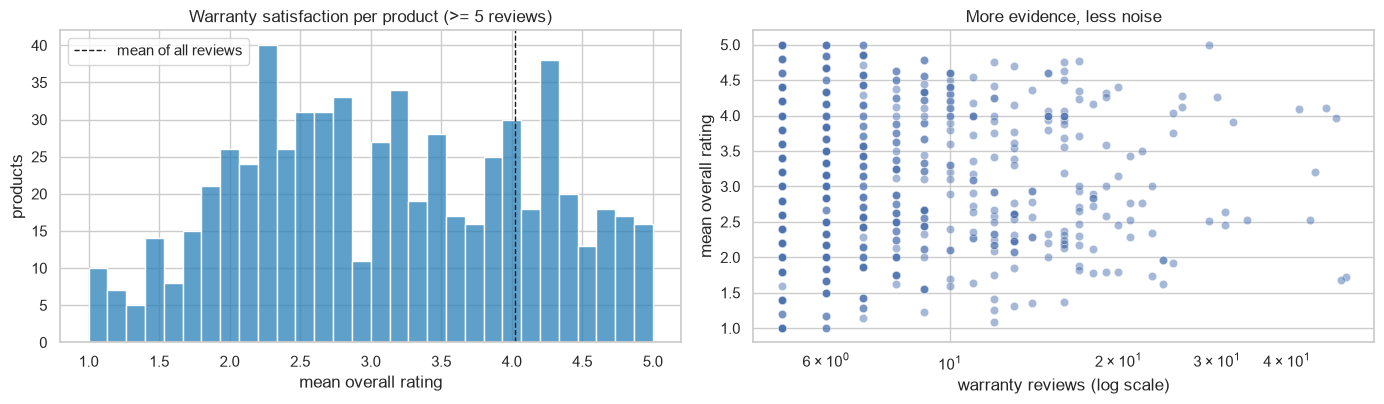

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.histplot(reliable["warranty_mean_overall"], bins=30, ax=axes[0], color="#2980b9")
axes[0].axvline(overall_mean, color="k", ls="--", lw=1, label="mean of all reviews")
axes[0].set(title=f"Warranty satisfaction per product (>= {MIN_REVIEWS} reviews)", xlabel="mean overall rating", ylabel="products")
axes[0].legend()

sns.scatterplot(data=reliable, x="n_warranty_reviews", y="warranty_mean_overall", alpha=0.5, ax=axes[1])
axes[1].set(xscale="log", title="More evidence, less noise", xlabel="warranty reviews (log scale)", ylabel="mean overall rating")
plt.tight_layout(); plt.show()

In [11]:
out = per_product[["asin", "brand", "title", "n_warranty_reviews", "warranty_mean_overall",
                   "product_mean_overall", "difference", "reliable"]]
out_path = config.OUTPUT_DIR / "warranty_satisfaction_by_product.csv"
out.to_csv(out_path, index=False)
print(f"saved {len(out):,} products -> {out_path}")

saved 10,158 products -> /Users/arshia_kh/Downloads/prj_nlp/files/amazon-sentiment/outputs/warranty_satisfaction_by_product.csv


## 5 · Limitations
* **Negation is not handled**: "no warranty", "the warranty is useless" and "great warranty" all count as a mention. The rating, not the sentence, carries the sentiment, so this is a topic filter and not an aspect-sentiment model.
* **`rma` is the weakest word of the final list.** It adds about 1,450 reviews that the spellings do not catch and some of them talk about ordinary returns rather than a warranty claim. The effect on the result is small: with the spelling words alone the mean rating of the matched reviews is 3.19 instead of 3.13.
* **Recall is limited** to the words in the final list; reviews that talk about "the 3-year coverage" without any of the words are missed. The embedding neighbours show how topical the surrounding vocabulary is, which is why we did not widen the list.
* **Few products have enough evidence** (≈ 640 of 90,715). Averages near the 5.0 ceiling or the 1.0 floor with 5–7 reviews are still noisy; look at `n_warranty_reviews` and `difference`.
* **Embeddings were trained on a sample** of 120k reviews for speed; a larger sample or `gensim.Word2Vec` could refine the neighbour list but would not change the decisions above, which were validated by reading hits.